# 05 Evaluation

In 04a and 04b, two races chose a winner each: **OLS** to predict consumption and **Logit** to predict if poor/not poor.
They both use the same 53 columns (Set A, without the village-level columns).

In [1]:
import sys
sys.path.append("..")   # the notebook finds the shared code in src/, one folder up

import os
import warnings
warnings.filterwarnings("ignore", message=".*penalty.*")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import PredefinedSplit

from src.utils import SEED, load_data, select_by_quota, recall_at_quota, within_village_auc
from src.features import SET_A, without_village_level, make_preprocessor

train, test = load_data()   # test is not used before this part 5
cv = PredefinedSplit(train["fold"])   # the same 5 village folds as in 03, 04a and 04b
os.makedirs("../outputs/figures", exist_ok=True)
print("train:", train.shape, "| villages:", train["hhea"].nunique(), "| SEED:", SEED)

train: (4090, 113) | villages: 512 | SEED: 40


## 1. Summarises all results for both races 04a and 04b, from set A and set B

Mean CV recall at the quota and within-village AUC, nubers come from outputs of the 4 notebooks.

| Race | Model | Set A | Set B |
|---|---|---|---|
| Regression (04a) | **OLS (winner)** | **56.1% (3.0)**, AUC 0.824 | **56.5% (2.8)**, AUC 0.828 |
| | Ridge | 56.1% | 57.0% |
| | Lasso | 56.2%, AUC 0.825 | 57.1%, AUC 0.834 |
| | Elastic Net | 56.2% | 56.9% |
| | Boosting | 56.1%, AUC 0.823 | 56.8%, AUC 0.830 |
| Classification (04b) | **Logit (winner)** | **56.2% (3.2)**, AUC 0.814 | **56.5% (4.0)**, AUC 0.825 |
| | Logit L2 | 56.0% | 56.5% |
| | Logit L1 | 56.0% | 56.9%, AUC 0.828 |
| | Boosting | 55.9%, AUC 0.824 | 55.4% |
| | Neural net | 55.8% | 56.6% |
| References (03) | Government formula | 54.0% (2.4), AUC 0.777 | |
| | Random | 36.4% | |
| | Perfect ranking | 68.6%, AUC 1.000 | |

- In both regression and classification and with both sets A and B, the models are are tied with the bests because their differences are smaller than the normal variation from luck. Therefore, the simplext model wins: OLS and Logit.
- Set B (+ 39 items) adds at most approximately one point, which is smaller than the spread across folds. The main comparison thus stays with set A.

## 2. The final run and the comparison between OLS and Logit

We fit the two winners again, fold by fold on the same villages, and also the two boosting models with the settings already chosen in 04a and 04b.


In [2]:
# Linear models (OLS, Logit): set A without the village-level columns, as in 04a and 04b
features = without_village_level(SET_A)     # 53 columns
X_train = train[features].astype(float)     # <NA> becomes NaN, filled in the pipeline

# Boosting: all of set A (with district, urban and village facilities), as in 04a and 04b
features_full = SET_A       # 66 columns
X_train_full = train[features_full].copy()
num_cols = [c for c in features_full if c != "kabu"]        # all columns except the district code
X_train_full[num_cols] = X_train_full[num_cols].astype(float)

# The two targets: the pairs differ only here
y_consumption = train["LOGCONSUMPTION"]     # regression: log consumption per person
y_poor = train["poor"].astype(int)          # classification: 1 = poor, 0 = not poor
print("features:", len(features), "| with village-level columns:", len(features_full))

features: 53 | with village-level columns: 66


In [3]:
# Settings chosen by the searches in 04a and 04b (set A), copied here so the models are identical
best_params_boost_reg = {"model__min_samples_leaf": 50, "model__max_iter": 200, "model__max_depth": 2,
                         "model__learning_rate": 0.1, "model__l2_regularization": 1}        # 04a, section 8
best_params_boost_clf = {"model__min_samples_leaf": 100, "model__max_iter": 800, "model__max_depth": 2,
                         "model__learning_rate": 0.05, "model__l2_regularization": 0.1}     # 04b, section 5

def make_models():
    """The four models with their data (new, unfitted copies every time it is called)."""
    ols = Pipeline([("prep", make_preprocessor(features, drop_first=True)),
                    ("model", LinearRegression())])
    logit = Pipeline([("prep", make_preprocessor(features, drop_first=True)),
                      ("model", LogisticRegression(penalty=None, max_iter=5000))])
    boost_reg = Pipeline([("prep", make_preprocessor(features_full, scale=False)),
                          ("model", HistGradientBoostingRegressor(early_stopping=False, random_state=SEED))])
    boost_reg.set_params(**best_params_boost_reg)
    boost_clf = Pipeline([("prep", make_preprocessor(features_full, scale=False)),
                          ("model", HistGradientBoostingClassifier(early_stopping=False, random_state=SEED))])
    boost_clf.set_params(**best_params_boost_clf)

    # higher_is_poorer: False = low predicted consumption is poor, True = high probability of being poor is poor
    return {
        "OLS":                    {"model": ols,       "X": X_train,      "y": y_consumption, "higher_is_poorer": False},
        "Logit":                  {"model": logit,     "X": X_train,      "y": y_poor,        "higher_is_poorer": True},
        "Boosting (consumption)": {"model": boost_reg, "X": X_train_full, "y": y_consumption, "higher_is_poorer": False},
        "Boosting (poverty)":     {"model": boost_clf, "X": X_train_full, "y": y_poor,        "higher_is_poorer": True},
    }

In [4]:
rng = np.random.default_rng(SEED)       # fixed seed, so the random baseline is the same every time
rows = []       # one row per model and fold

for k, (train_idx, val_idx) in enumerate(cv.split()):       # k = fold number (0 to 4)
    val = train.iloc[val_idx].copy()        # validation villages of fold k

    # 1. The four models: learn on the other 4 folds, predict fold k
    for name, m in make_models().items():
        m["model"].fit(m["X"].iloc[train_idx], m["y"].iloc[train_idx])
        if m["higher_is_poorer"]:
            val[name] = m["model"].predict_proba(m["X"].iloc[val_idx])[:, 1]        # probability of being poor
        else:
            val[name] = m["model"].predict(m["X"].iloc[val_idx])        # predicted log consumption
        selected = select_by_quota(val, name, higher_is_poorer=m["higher_is_poorer"])
        rows.append({"model": name, "fold": k, "recall": recall_at_quota(val, selected),
                     "within_auc": within_village_auc(val, name, higher_is_poorer=m["higher_is_poorer"])})

    # 2. References (same as in 03): government formula and perfect ranking
    for name, score in [("Government formula", "pcexppred"), ("Perfect ranking", "LOGCONSUMPTION")]:
        selected = select_by_quota(val, score, higher_is_poorer=False)      # low consumption = poor
        rows.append({"model": name, "fold": k, "recall": recall_at_quota(val, selected),
                     "within_auc": within_village_auc(val, score, higher_is_poorer=False)})

    # 3. Random selection: 100 draws, because one draw alone depends on luck
    random_recalls = []
    for i in range(100):
        val["random_score"] = rng.random(len(val))
        random_recalls.append(recall_at_quota(val, select_by_quota(val, "random_score", higher_is_poorer=True)))
    rows.append({"model": "Random", "fold": k, "recall": np.mean(random_recalls), "within_auc": 0.5})
    # why 0.5: a random ranking orders a poor/non-poor pair correctly half of the time

cv_results = pd.DataFrame(rows)
by_fold = cv_results.pivot(index="fold", columns="model", values="recall")      # recall: one row per fold
display(by_fold.round(3))

model,Boosting (consumption),Boosting (poverty),Government formula,Logit,OLS,Perfect ranking,Random
fold,,,,,,,
0,0.582,0.579,0.559,0.589,0.589,0.716,0.370
1,0.582,0.597,0.544,0.582,0.582,0.682,0.374
2,0.548,0.525,0.548,0.538,0.545,0.664,0.353
3,0.583,0.583,0.552,0.583,0.573,0.729,0.382
4,0.509,0.513,0.498,0.516,0.516,0.639,0.341


In [5]:
# Mean and standard deviation across the 5 folds, best recall first
summary = cv_results.groupby("model")[["recall", "within_auc"]].agg(["mean", "std"])
summary = summary.sort_values(("recall", "mean"), ascending=False)

# Share of the possible improvement: random = 0%, perfect ranking = 100%
r_random = summary[("recall", "mean")]["Random"]
r_perfect = summary[("recall", "mean")]["Perfect ranking"]
summary["share of possible gain"] = (summary[("recall", "mean")] - r_random) / (r_perfect - r_random)
display(summary.round(3))

/var/folders/c4/tgg8_grs3mb8cwzhfy7m2yp80000gn/T/ipykernel_94933/1899567244.py:8: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  summary["share of possible gain"] = (summary[("recall", "mean")] - r_random) / (r_perfect - r_random)


recall        within_auc        share of possible gain
                         mean    std       mean    std                       
model                                                                        
Perfect ranking         0.686  0.037      1.000  0.000                  1.000
Logit                   0.562  0.032      0.814  0.027                  0.613
OLS                     0.561  0.030      0.824  0.025                  0.611
Boosting (consumption)  0.561  0.033      0.823  0.022                  0.611
Boosting (poverty)      0.559  0.038      0.824  0.026                  0.606
Government formula      0.540  0.024      0.777  0.023                  0.547
Random                  0.364  0.017      0.500  0.000                  0.000

## 3. Comparison predicting consumption with predicting poverty directly

In [6]:
# Paired comparison: the same villages are in every fold, so we compare fold by fold
pairs = {
    "OLS - Logit (linear pair)":       ("OLS", "Logit"),
    "Boosting: consumption - poverty": ("Boosting (consumption)", "Boosting (poverty)"),
    "OLS - Government formula":        ("OLS", "Government formula"),
    "Logit - Government formula":      ("Logit", "Government formula"),
}

rows = []
for pair_name, (a, b) in pairs.items():
    diff = by_fold[a] - by_fold[b]   # difference in recall in each of the 5 folds
    rows.append([pair_name, diff.mean(), diff.std(), (diff > 0).sum()])

paired = pd.DataFrame(rows, columns=["Comparison", "Mean difference", "Std across folds",
                                     "Folds above 0 (of 5)"]).set_index("Comparison")
display(paired.round(3))

,Mean difference,Std across folds,Folds above 0 (of 5)
Comparison,,,
OLS - Logit (linear pair),-0.001,0.006,1
Boosting: consumption - poverty,0.001,0.014,2
OLS - Government formula,0.021,0.016,4
Logit - Government formula,0.021,0.019,4


## 4. Draws the final figure

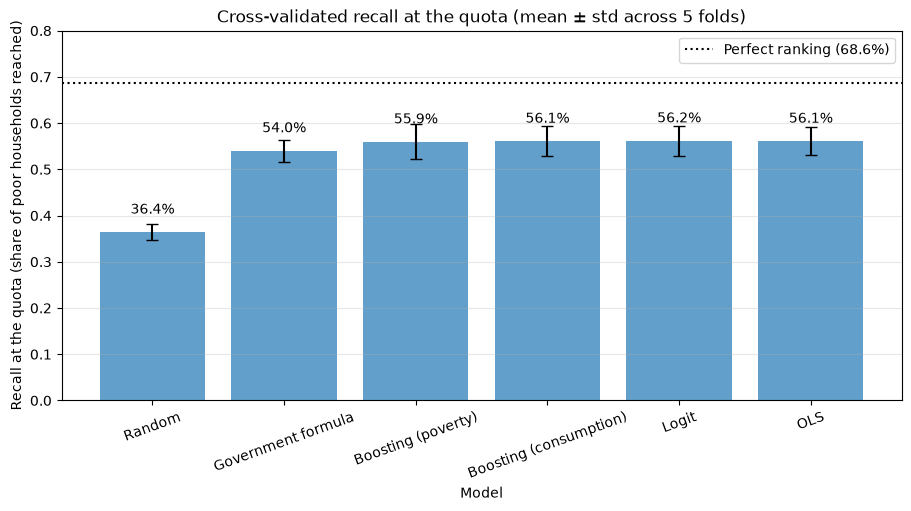

In [7]:
order = ["Random", "Government formula", "Boosting (poverty)", "Boosting (consumption)", "Logit", "OLS"]
means = summary[("recall", "mean")][order]
stds = summary[("recall", "std")][order]

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.bar(order, means, yerr=stds, capsize=4, alpha=0.7)                       # mean ± std across the 5 folds
ax.axhline(r_perfect, color="black", linestyle=":", label=f"Perfect ranking ({r_perfect:.1%})")   # the ceiling
for i, m in enumerate(means):
    ax.text(i, m + 0.04, f"{m:.1%}", ha="center")                           # value above each bar

ax.set_ylim(0, 0.8)
ax.set_xlabel("Model")
ax.set_ylabel("Recall at the quota (share of poor households reached)")
ax.set_title("Cross-validated recall at the quota (mean ± std across 5 folds)")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.savefig("../outputs/figures/final_cv_recall.png", dpi=200, bbox_inches="tight")   # for the report and slides
plt.show()

**Results:**

- **The final is very tie:** OLS finds 56.1 while Logit finds 56.2 poour households out of 100. The diference fold by fold is 0 and never more than one point (mean = -0.001, std = 0.6)
- **There is no difference between predicting consumption or poverty:** boosting gives almost the same answer (55.9% vs 56.1%). Both rank the households within a village in almost the same order, so the target does not matter.
- **Both winners beat the government formula** by 2 percentage points, better in 4 of the 5 folds, and use 61% (0.611 and 0.613) of the possible improvement, against only 55% for the government (0.547).
- **Final winner**: 

In [8]:
## 5. Uses the test villages **once**, at the very end